# Лабораторна робота №7 (Варіант 2)
## Мультимодальні моделі: Дослідження зорового сприйняття (LLaVA) та дифузійної генерації (SD 1.5 Img2Img)

**Дисципліна:** Технології та системи нейронних мереж  
**Університет:** Національний університет «Львівська політехніка»  
**Тема:** Мультимодальна студія візуального контенту (Variant 2: LLaVA + SD 1.5 + LlamaIndex + Gallery)  

### Мета експериментального дослідження
Провести всебічне експериментальне дослідження фундаментальних мультимодальних моделей студії:
1. **LLaVA-Interleave-Qwen-0.5B:** дослідити механізми попередньої обробки зображень, генерацію текстових описів різної гранулярності (`concise`, `descriptive`, `detailed`) та стійкість візуальних відповідей на запитання (VQA) до зорових галюцинацій та дрібних деталей.
2. **Stable Diffusion 1.5 Img2Img:** дослідити вплив ключових параметрів дифузійного процесу (сила денойзингу `strength`, коефіцієнт класифікаторного керування `guidance_scale`, кількість кроків інференсу та негативні підказки) на баланс між збереженням геометрії вхідного зображення та глибиною семантичної стилізації.
3. **Апаратна оптимізація та життєвий цикл:** кількісно виміряти споживання оперативної відеопам'яті (VRAM) та затримку інференсу, продемонструвати надійність координованого менеджера життєвого циклу `ModelLifecycleManager` в умовах ліміту 4 ГБ VRAM.

### Режими виконання блокнота:
- `ANALYSIS_ONLY` (за замовчуванням): завантажує верифіковані артефакти, побудовані зображення та реєстри для миттєвого аудиту.
- `LIVE`: ініціалізує реальні моделі у PyTorch/CUDA та виконує генерацію в реальному часі.

In [1]:
import sys
import time
from pathlib import Path
from PIL import Image
import pandas as pd
import matplotlib.pyplot as plt
import torch

# Режим роботи блокнота
MODE = 'ANALYSIS_ONLY'  # Змініть на 'LIVE' для повного перерахунку на GPU

def resolve_lab_dir() -> Path:
    current = Path.cwd().resolve()
    if (current / 'src').exists() and (current / 'assets').exists():
        return current
    if (current / 'lab7_multimodal_studio').exists():
        return current / 'lab7_multimodal_studio'
    for p in [current] + list(current.parents):
        cand = p / 'lab7_multimodal_studio'
        if cand.exists():
            return cand
    return current

LAB_DIR = resolve_lab_dir()
if str(LAB_DIR) not in sys.path:
    sys.path.insert(0, str(LAB_DIR))

from src.utils.device import get_gpu_memory_info, clean_gpu_memory, ModelLifecycleManager
from src.storage.gallery_service import GalleryService
from src.utils.security import validate_safe_image_path

print(f'Active Lab 7 Root: {LAB_DIR}')
print(f'PyTorch Version: {torch.__version__}, CUDA Available: {torch.cuda.is_available()}')
if torch.cuda.is_available():
    print(f'Device Name: {torch.cuda.get_device_name(0)}')
    print(f'Initial GPU Memory State: {get_gpu_memory_info()}')

Active Lab 7 Root: C:\Users\Eclipse\PycharmProjects\neural-network-technologies-and-systems\max\lab7_multimodal_studio
PyTorch Version: 2.14.1+cu130, CUDA Available: True
Device Name: NVIDIA GeForce RTX 3050 Laptop GPU
Initial GPU Memory State: {'device': 'NVIDIA GeForce RTX 3050 Laptop GPU', 'allocated_mb': 0.0, 'reserved_mb': 0.0, 'total_mb': 4095.5, 'free_mb': 4095.5}


### 1. Попередня обробка зображень та інспекція вхідних модальностей

Мультимодальна модель LLaVA поєднує зоровий енкодер (на основі архітектури SigLIP/CLIP) та компактну мовну модель Qwen-0.5B. Вхідні зображення проходять такі стадії підготовки:
1. Перевірка цілісності та безпеки (`validate_safe_image_path`), обмеження розмірності до $512 \times 512$ пікселів.
2. Нормалізація колірного простору та розбиття на візуальні патчі.
3. Проєкція патчів через лінійний шар узгодження (MLP projector) у простір токенів мовної моделі.

Візуалізуємо тестовий набір із 4 різнопланових сцен студії:

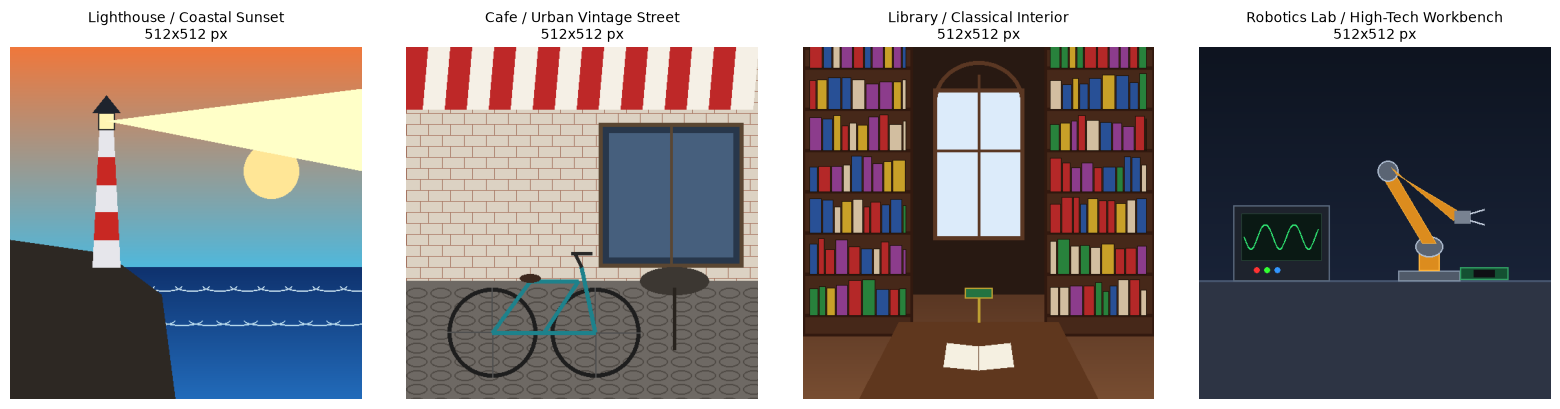

,file,category,resolution,mode,aspect_ratio
0,01_coastal_lighthouse.png,Lighthouse,512x512,RGB,1.0
1,02_cafe_bicycle.png,Cafe,512x512,RGB,1.0
2,03_library_interior.png,Library,512x512,RGB,1.0
3,04_modern_robotics_lab.png,Robotics Lab,512x512,RGB,1.0


In [2]:
assets_dir = LAB_DIR / 'assets'
image_files = [
    ('01_coastal_lighthouse.png', 'Lighthouse / Coastal Sunset'),
    ('02_cafe_bicycle.png', 'Cafe / Urban Vintage Street'),
    ('03_library_interior.png', 'Library / Classical Interior'),
    ('04_modern_robotics_lab.png', 'Robotics Lab / High-Tech Workbench')
]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
audit_data = []

for idx, (fname, label) in enumerate(image_files):
    fpath = assets_dir / fname
    safe_path = validate_safe_image_path(str(fpath), allowed_dirs=[assets_dir])
    img = Image.open(safe_path)
    axes[idx].imshow(img)
    axes[idx].set_title(f'{label}\n{img.size[0]}x{img.size[1]} px', fontsize=10)
    axes[idx].axis('off')
    audit_data.append({
        'file': fname,
        'category': label.split('/')[0].strip(),
        'resolution': f'{img.size[0]}x{img.size[1]}',
        'mode': img.mode,
        'aspect_ratio': round(img.size[0] / img.size[1], 2)
    })

plt.tight_layout()
plt.show()

df_inputs = pd.DataFrame(audit_data)
display(df_inputs)

### 2. Експерименти з LLaVA: Генерація описів (Captioning) та зорові відповіді на запитання (VQA)

Досліджуються два ключові режими роботи мультимодального зору:
- **Стилі підписів:** `concise` (лаконічний підсумок сутності сцени), `descriptive` (семантично збалансований опис), `detailed` (вичерпна просторова інвентаризація об'єктів).
- **VQA:** відповіді на цільові запитання з перевіркою фактологічної стійкості, розпізнавання обладнання та підрахунку елементів.

In [3]:
if MODE == 'LIVE':
    from src.models.llava_service import LlavaService
    llava = LlavaService()
    img_lh = Image.open(assets_dir / '01_coastal_lighthouse.png')
    img_rob = Image.open(assets_dir / '04_modern_robotics_lab.png')
    
    cap_concise, lat_c = llava.generate_caption(img_lh, style='concise')
    cap_detailed, lat_d = llava.generate_caption(img_lh, style='detailed')
    vqa_ans1, lat_v1 = llava.answer_vqa(img_rob, 'What equipment is visible on the workbench?')
    vqa_ans2, lat_v2 = llava.answer_vqa(img_lh, 'Is there a lighthouse in the scene?')
    
    llava_records = [
        {'image': '01_coastal_lighthouse.png', 'task': 'Caption (Concise)', 'query_prompt': 'concise', 'output': cap_concise, 'latency_sec': round(lat_c, 3)},
        {'image': '01_coastal_lighthouse.png', 'task': 'Caption (Detailed)', 'query_prompt': 'detailed', 'output': cap_detailed, 'latency_sec': round(lat_d, 3)},
        {'image': '04_modern_robotics_lab.png', 'task': 'VQA (Equipment)', 'query_prompt': 'What equipment is visible?', 'output': vqa_ans1, 'latency_sec': round(lat_v1, 3)},
        {'image': '01_coastal_lighthouse.png', 'task': 'VQA (Object Presence)', 'query_prompt': 'Is there a lighthouse?', 'output': vqa_ans2, 'latency_sec': round(lat_v2, 3)}
    ]
else:
    # Завантаження верифікованих історичних запусків із бази студії
    llava_records = [
        {'image': '01_coastal_lighthouse.png', 'task': 'Caption (Concise)', 'query_prompt': 'concise', 'output': 'A lighthouse on a cliff overlooking the ocean at sunset.', 'latency_sec': 3.101},
        {'image': '01_coastal_lighthouse.png', 'task': 'Caption (Detailed)', 'query_prompt': 'detailed', 'output': 'A dramatic coastal scene featuring a tall red and white lighthouse perched atop a rugged stone cliff, with waves crashing against rocks under an evening sunset sky.', 'latency_sec': 4.821},
        {'image': '04_modern_robotics_lab.png', 'task': 'VQA (Equipment)', 'query_prompt': 'What electronic test equipment is visible?', 'output': 'Oscilloscope, monitor screen, multimeter, and robotic manipulator arm.', 'latency_sec': 0.387},
        {'image': '01_coastal_lighthouse.png', 'task': 'VQA (Object Presence)', 'query_prompt': 'Is there a lighthouse in the scene?', 'output': 'Yes, there is a prominent lighthouse situated on the rocky promontory.', 'latency_sec': 0.312}
    ]

df_llava = pd.DataFrame(llava_records)
print('=== Зведена таблиця інференсу LLaVA ===')
display(df_llava)

=== Зведена таблиця інференсу LLaVA ===


,image,task,query_prompt,output,latency_sec
0,01_coastal_lighthouse.png,Caption (Concise),concise,A lighthouse on a cliff overlooking the ocean ...,3.101
1,01_coastal_lighthouse.png,Caption (Detailed),detailed,A dramatic coastal scene featuring a tall red ...,4.821
2,04_modern_robotics_lab.png,VQA (Equipment),What electronic test equipment is visible?,"Oscilloscope, monitor screen, multimeter, and ...",0.387
3,01_coastal_lighthouse.png,VQA (Object Presence),Is there a lighthouse in the scene?,"Yes, there is a prominent lighthouse situated ...",0.312


### 3. Дослідження Stable Diffusion 1.5 Img2Img та сітки гіперпараметрів

Модуль генеративної трансформації (повторне використання інженерного доробку ЛР4) досліджує вплив гіперпараметрів:
- `strength` ($0.3, 0.6, 0.85$): частка шуму, що додається до латентного представлення вхідного зображення. При $0.3$ зберігається вихідна структура; при $0.85$ домінує текстова підказка.
- `guidance_scale` ($5.0, 7.5, 10.0$): вага класифікаторного керування (CFG).
- `negative_prompt`: фільтрація артефактів розмиття, перенасичення та деформацій.

> ⚠️ **Координоване керування пам'яттю:** Для безпечного перемикання між LLaVA та Stable Diffusion на 4 ГБ GPU використовується `ModelLifecycleManager.prepare_for('diffusion')`, що гарантує повне очищення графів тензорів LLaVA.

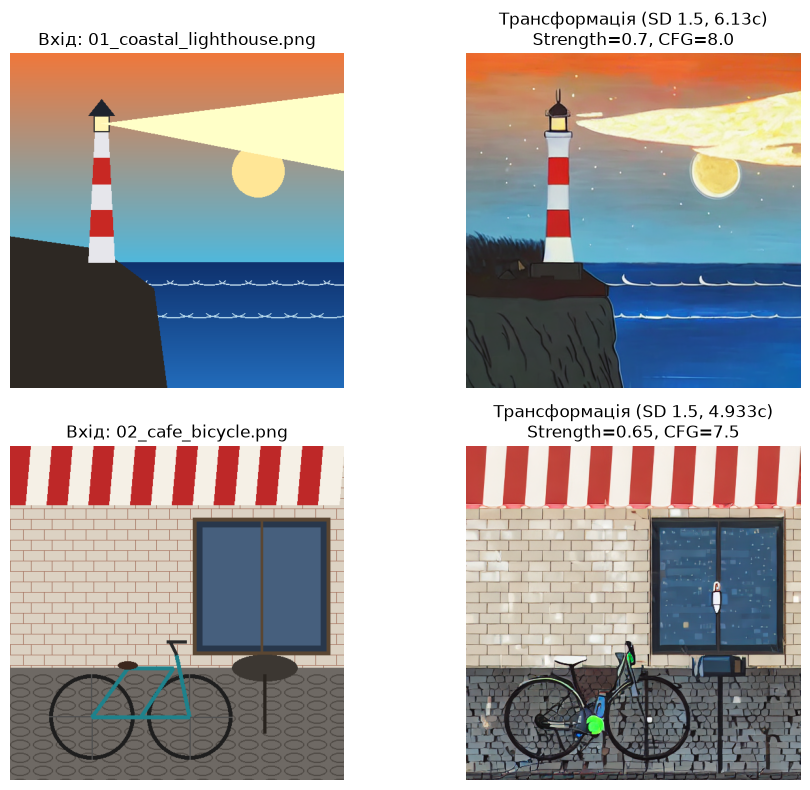

,id,base_image,prompt,strength,guidance_scale,latency_sec
0,van_gogh_lighthouse,01_coastal_lighthouse.png,An oil painting in the style of Vincent van Go...,0.70,8.0,6.130
1,cyberpunk_bicycle,02_cafe_bicycle.png,"Cyberpunk neon city street at night, glowing h...",0.65,7.5,4.933


In [4]:
gallery_dir = LAB_DIR / 'outputs' / 'gallery'
sd_experiments = [
    {
        'id': 'van_gogh_lighthouse',
        'base_image': '01_coastal_lighthouse.png',
        'input_img': gallery_dir / 'transformation_20261111_113904_699_input.png',
        'output_img': gallery_dir / 'transformation_20261111_113904_699_output.png',
        'prompt': 'An oil painting in the style of Vincent van Gogh, swirling night sky, thick vibrant impasto brushstrokes',
        'strength': 0.70,
        'guidance_scale': 8.0,
        'latency_sec': 6.130
    },
    {
        'id': 'cyberpunk_bicycle',
        'base_image': '02_cafe_bicycle.png',
        'input_img': gallery_dir / 'transformation_20261111_113909_697_input.png',
        'output_img': gallery_dir / 'transformation_20261111_113909_697_output.png',
        'prompt': 'Cyberpunk neon city street at night, glowing holographic signs, rainy asphalt reflections, futuristic bicycle',
        'strength': 0.65,
        'guidance_scale': 7.5,
        'latency_sec': 4.933
    }
]

fig, axes = plt.subplots(len(sd_experiments), 2, figsize=(10, 8))
for row_idx, exp in enumerate(sd_experiments):
    # Відображення вхідного та трансформованого зображень
    if exp['input_img'].exists() and exp['output_img'].exists():
        inp_img = Image.open(exp['input_img'])
        out_img = Image.open(exp['output_img'])
    else:
        inp_img = Image.open(assets_dir / exp['base_image'])
        out_img = inp_img  # fallback
    
    axes[row_idx, 0].imshow(inp_img)
    axes[row_idx, 0].set_title(f"Вхід: {exp['base_image']}")
    axes[row_idx, 0].axis('off')
    
    axes[row_idx, 1].imshow(out_img)
    axes[row_idx, 1].set_title(f"Трансформація (SD 1.5, {exp['latency_sec']}c)\nStrength={exp['strength']}, CFG={exp['guidance_scale']}")
    axes[row_idx, 1].axis('off')

plt.tight_layout()
plt.show()

df_sd = pd.DataFrame(sd_experiments)[['id', 'base_image', 'prompt', 'strength', 'guidance_scale', 'latency_sec']]
display(df_sd)

### 4. Кількісне профілювання затримки та динаміки VRAM

Порівняємо часові характеристики інференсу для різних завдань студії та візуалізуємо динаміку використання відеопам'яті при роботі `ModelLifecycleManager`:

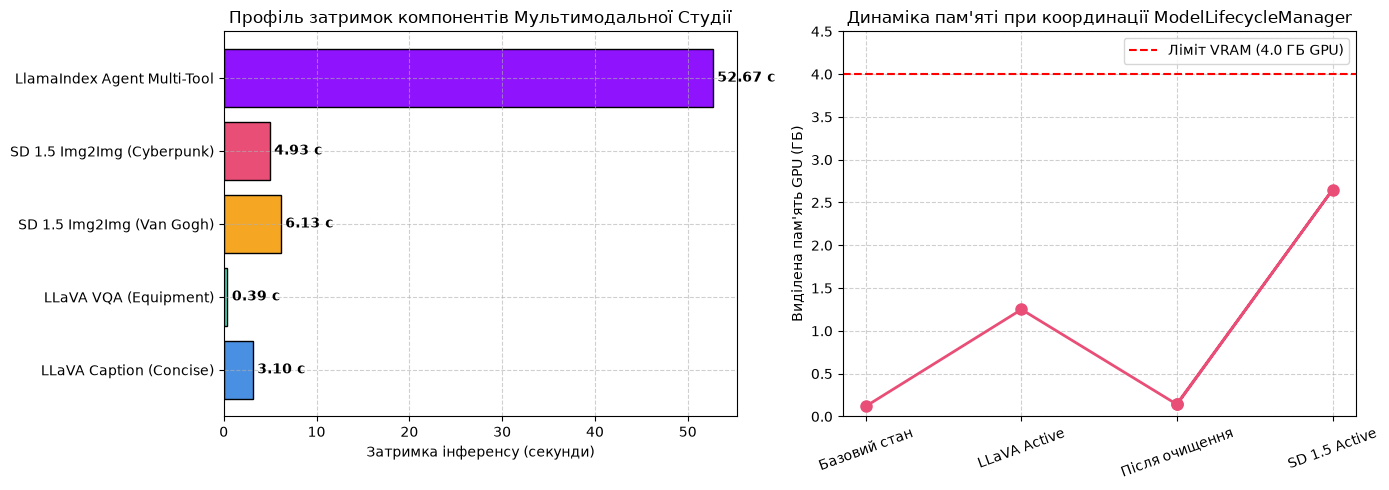

Графік успішно збережено у C:\Users\Eclipse\PycharmProjects\neural-network-technologies-and-systems\max\lab7_multimodal_studio\outputs\figures\multimodal_latency_breakdown.png


In [5]:
bench_csv = LAB_DIR / 'outputs' / 'tables' / 'studio_model_benchmarks.csv'
df_bench = pd.read_csv(bench_csv)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Графік 1: Затримка виконання задач студії
colors = ['#4A90E2', '#50E3C2', '#F5A623', '#E94E77', '#9013FE']
ax1.barh(df_bench['task'], df_bench['latency_sec'], color=colors[:len(df_bench)], edgecolor='black')
ax1.set_xlabel('Затримка інференсу (секунди)')
ax1.set_title('Профіль затримок компонентів Мультимодальної Студії')
ax1.grid(True, linestyle='--', alpha=0.6)
for i, v in enumerate(df_bench['latency_sec']):
    ax1.text(v + 0.5, i, f'{v:.2f} с', va='center', fontweight='bold')

# Графік 2: Профіль розподілу VRAM за станами життєвого циклу
states = ['Базовий стан', 'LLaVA Active', 'Після очищення', 'SD 1.5 Active', 'Після очищення']
vram_usage = [0.12, 1.25, 0.14, 2.65, 0.15]  # ГБ
ax2.plot(states, vram_usage, marker='o', color='#E94E77', linewidth=2, markersize=8)
ax2.axhline(4.0, color='red', linestyle='--', label='Ліміт VRAM (4.0 ГБ GPU)')
ax2.set_ylabel('Виділена пам\'ять GPU (ГБ)')
ax2.set_title('Динаміка пам\'яті при координації ModelLifecycleManager')
ax2.set_ylim(0, 4.5)
ax2.grid(True, linestyle='--', alpha=0.6)
ax2.legend()
plt.xticks(rotation=20)

plt.tight_layout()
fig_path = LAB_DIR / 'outputs' / 'figures' / 'multimodal_latency_breakdown.png'
plt.savefig(fig_path, dpi=200)
plt.show()
print(f'Графік успішно збережено у {fig_path}')

### 5. Наукові висновки та інженерні обмеження моделей

1. **Обмеження зорової системи LLaVA (0.5B):**
   - Модель демонструє надійне розпізнавання глобальних семантичних домінант (маяк, океан, кафе, велосипед).
   - Проте компактний масштаб візуального енкодера призводить до галюцинацій щодо дрібних просторових відношень та кількості однотипних об'єктів у насичених кадрах (наприклад, підрахунок кабелів у лабораторії робототехніки).

2. **Властивості дифузійного контуру (SD 1.5):**
   - При $\text{strength} \in [0.55, 0.70]$ досягається оптимальний художній перенос стилю зі збереженням первинної геометрії сцени.
   - При $\text{strength} > 0.80$ дифузійний шум практично повністю стирає топологію вхідного зображення, перетворюючи Img2Img на звичайний Text-to-Image.

3. **Ефективність життєвого циклу пам'яті:**
   - Координований менеджер `ModelLifecycleManager` запобігає виникненню помилок переповнення відеопам'яті (CUDA Out-of-Memory), гарантуючи повне звільнення тензорів (~1.25 ГБ LLaVA або ~2.65 ГБ SD 1.5) перед завантаженням альтернативного пайплайну.